# Сравнение операторов выделения границ почки

In [55]:
from pathlib import Path

import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

MEDIAN_KERNEL = 5
GAUSSIAN_KERNEL = (5, 5)

SAMPLE_TYPES = {
    "000001": "УЗИ",
    "000027": "УЗИ",
    "000032": "УЗИ",
    "000036": "КТ",
}


In [56]:
def read_grayscale(path):
    image = cv.imread(str(path), cv.IMREAD_GRAYSCALE)
    return image


samples = {}

for sample_id, scan_type in SAMPLE_TYPES.items():
    image = read_grayscale(Path(f"img_{sample_id}.png"))
    mask = read_grayscale(Path(f"mask_{sample_id}.png"))

    samples[sample_id] = {
        "type": scan_type,
        "image": image,
        "mask": mask,
    }




## Проверка изображений и масок


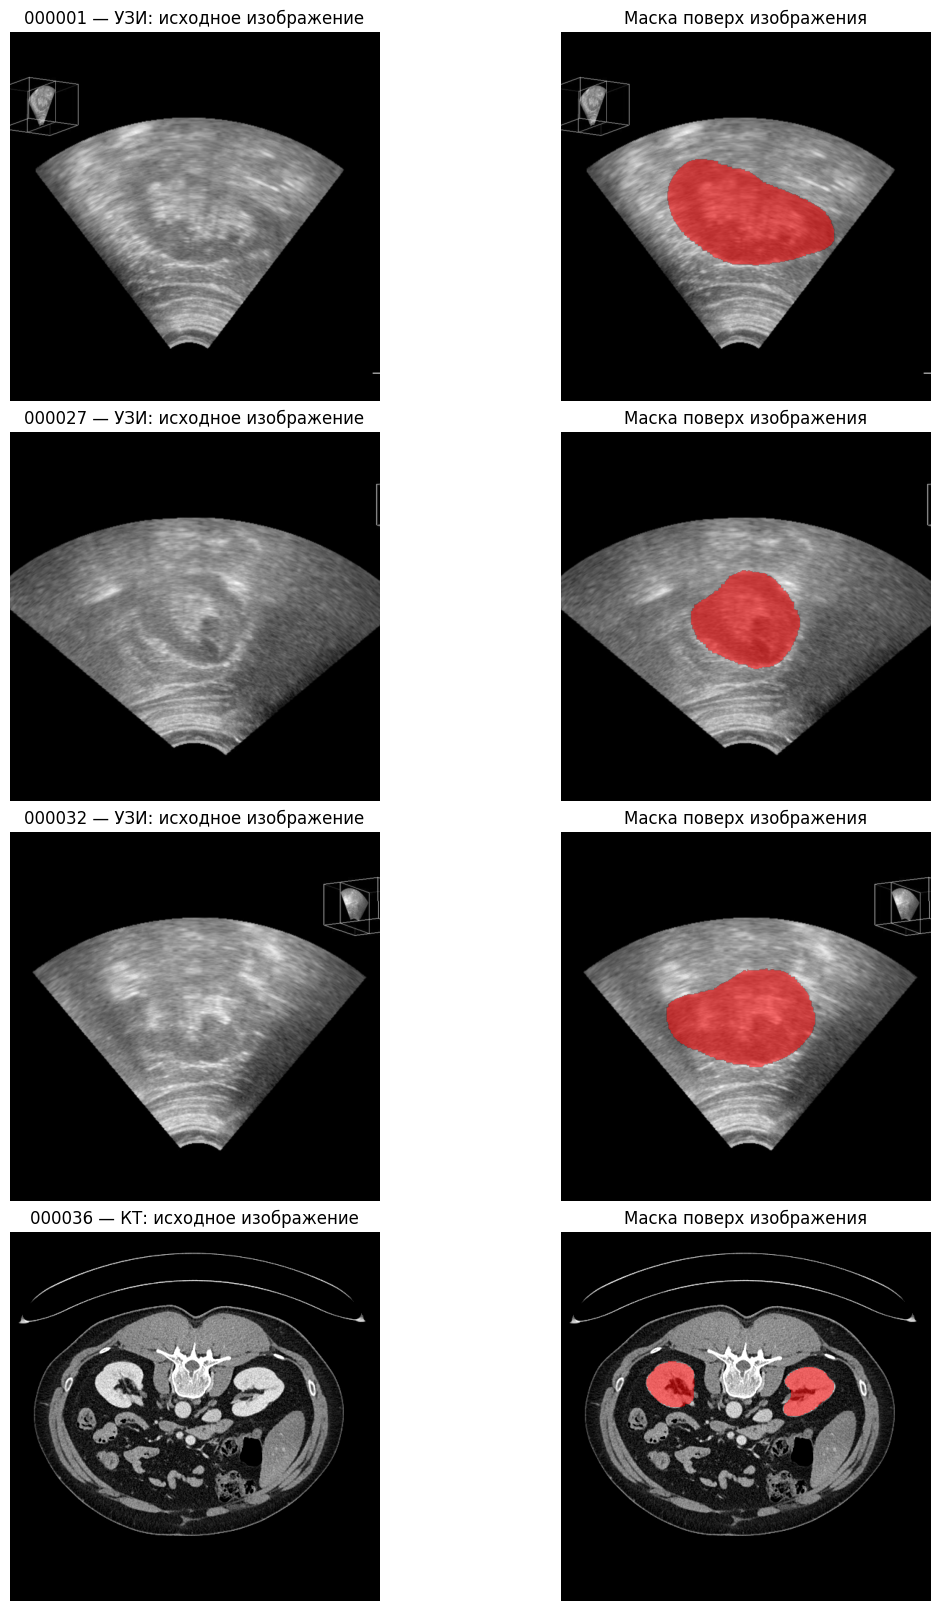

In [57]:
fig, axes = plt.subplots(
    len(samples),
    2,
    figsize=(11, 4 * len(samples)),
    constrained_layout=True,
)

for row, (sample_id, sample) in enumerate(samples.items()):
    axes[row, 0].imshow(sample["image"], cmap="gray", vmin=0, vmax=255)
    axes[row, 0].set_title(f'{sample_id} — {sample["type"]}: исходное изображение')

    mask_overlay = np.ma.masked_where(sample["mask"] == 0, sample["mask"])
    axes[row, 1].imshow(sample["image"], cmap="gray", vmin=0, vmax=255)
    axes[row, 1].imshow(mask_overlay, cmap="autumn", alpha=0.55)
    axes[row, 1].set_title("Маска поверх изображения")

    for ax in axes[row]:
        ax.axis("off")

plt.show()


## Операторы и параметры


In [58]:
OPERATOR_KERNELS = {
    "Собель": (
        np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=np.float64),
        np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], dtype=np.float64),
    ),
    "Щарр": (
        np.array([[-3, 0, 3], [-10, 0, 10], [-3, 0, 3]], dtype=np.float64),
        np.array([[-3, -10, -3], [0, 0, 0], [3, 10, 3]], dtype=np.float64),
    ),
    "Прюитт": (
        np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], dtype=np.float64),
        np.array([[-1, -1, -1], [0, 0, 0], [1, 1, 1]], dtype=np.float64),
    ),
}


def gradient_magnitude(image, kernel_x, kernel_y):
    gradient_x = cv.filter2D(image, cv.CV_64F, kernel_x)
    gradient_y = cv.filter2D(image, cv.CV_64F, kernel_y)
    magnitude = np.sqrt(gradient_x ** 2 + gradient_y ** 2)
    magnitude = cv.normalize(magnitude, None, 0, 255, cv.NORM_MINMAX)
    return magnitude.astype(np.uint8)


def apply_blur(image, filter_name, sigma=None):
    if filter_name == "Медианный":
        return cv.medianBlur(image, 5)
    return cv.GaussianBlur(image, (5, 5), sigma)


def format_parameters(params):
    parts = ["ядро 5x5"]
    if "sigma" in params:
        parts.append(f"sigma={params['sigma']}")
    if "threshold" in params:
        parts.append(f"порог={params['threshold']}")
    else:
        parts.append(f"пороги={params['low']}/{params['high']}")
    return ", ".join(parts)


def process_combination(image, combination, params):
    filter_name, operator = combination.split(" + ")
    filtered = apply_blur(image, filter_name, params.get("sigma"))

    if operator == "Кэнни":
        return cv.Canny(filtered, params["low"], params["high"], L2gradient=True)

    kernel_x, kernel_y = OPERATOR_KERNELS[operator]
    magnitude = gradient_magnitude(filtered, kernel_x, kernel_y)
    return cv.threshold(
        magnitude, params["threshold"], 255, cv.THRESH_BINARY
    )[1]


## Обработка снимков


In [59]:
PARAMETERS = {
    "000001": {
        "Медианный + Собель": {"threshold": 20},
        "Медианный + Щарр": {"threshold": 20},
        "Медианный + Прюитт": {"threshold": 15},
        "Медианный + Кэнни": {"low": 30, "high": 70},
        "Гауссов + Собель": {"sigma": 1.0, "threshold": 20},
        "Гауссов + Щарр": {"sigma": 1.2, "threshold": 25},
        "Гауссов + Прюитт": {"sigma": 2.0, "threshold": 30},
        "Гауссов + Кэнни": {"sigma": 2.0, "low": 20, "high": 50},
    },
    "000027": {
        "Медианный + Собель": {"threshold": 20},
        "Медианный + Щарр": {"threshold": 20},
        "Медианный + Прюитт": {"threshold": 20},
        "Медианный + Кэнни": {"low": 40, "high": 70},
        "Гауссов + Собель": {"sigma": 1.5, "threshold": 30},
        "Гауссов + Щарр": {"sigma": 1.5, "threshold": 30},
        "Гауссов + Прюитт": {"sigma": 1.5, "threshold": 30},
        "Гауссов + Кэнни": {"sigma": 1.2, "low": 30, "high": 70},
    },
    "000032": {
        "Медианный + Собель": {"threshold": 20},
        "Медианный + Щарр": {"threshold": 15},
        "Медианный + Прюитт": {"threshold": 15},
        "Медианный + Кэнни": {"low": 50, "high": 70},
        "Гауссов + Собель": {"sigma": 2.0, "threshold": 37},
        "Гауссов + Щарр": {"sigma": 2.0, "threshold": 35},
        "Гауссов + Прюитт": {"sigma": 2.0, "threshold": 30},
        "Гауссов + Кэнни": {"sigma": 1.2, "low": 50, "high": 70},
    },
    "000036": {
        "Медианный + Собель": {"threshold": 135},
        "Медианный + Щарр": {"threshold": 125},
        "Медианный + Прюитт": {"threshold": 135},
        "Медианный + Кэнни": {"low": 200, "high": 500},
        "Гауссов + Собель": {"sigma": 2.0, "threshold": 165},
        "Гауссов + Щарр": {"sigma": 2.0, "threshold": 165},
        "Гауссов + Прюитт": {"sigma": 2.0, "threshold": 165},
        "Гауссов + Кэнни": {"sigma": 2.0, "low": 200, "high": 400},
    },
}

processed = {}
for sample_id, sample in samples.items():
    processed[sample_id] = {}
    
    for combination, params in PARAMETERS[sample_id].items():
        processed[sample_id][combination] = {
            "image": process_combination(sample["image"], combination, params),
            "params": params,
        }


## Сравнение результатов


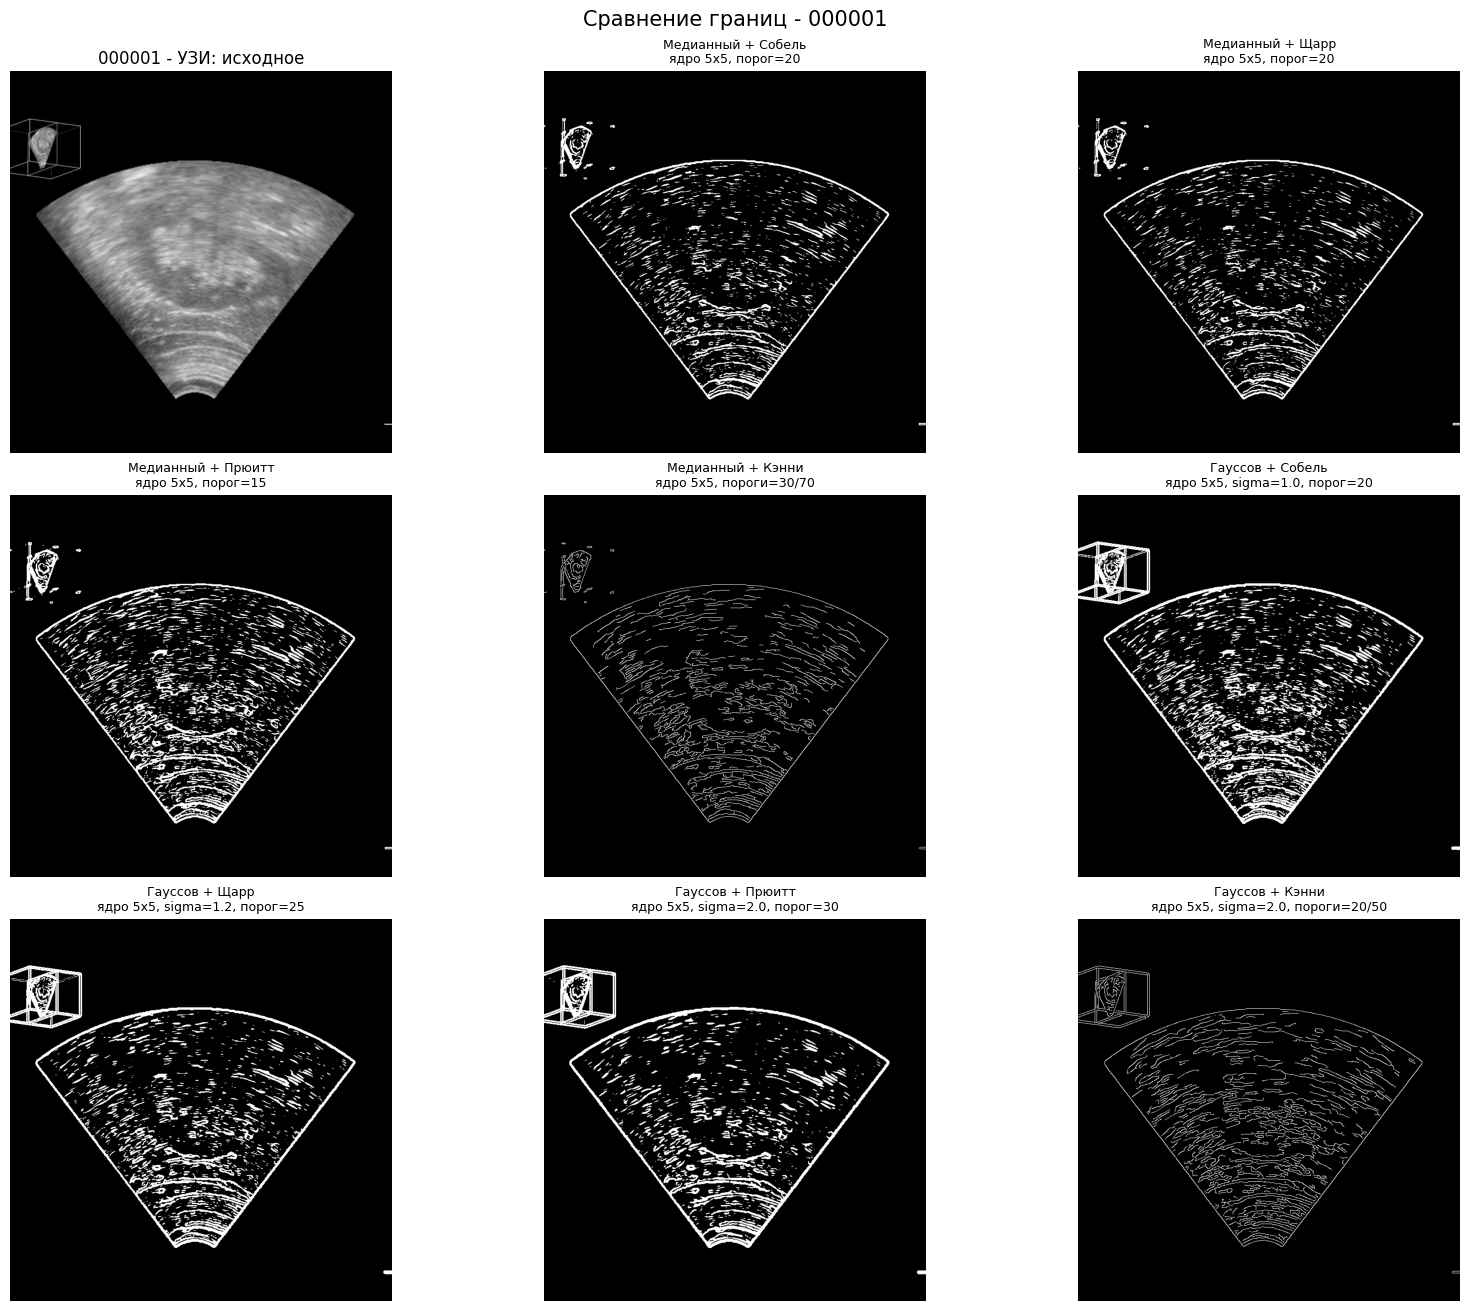

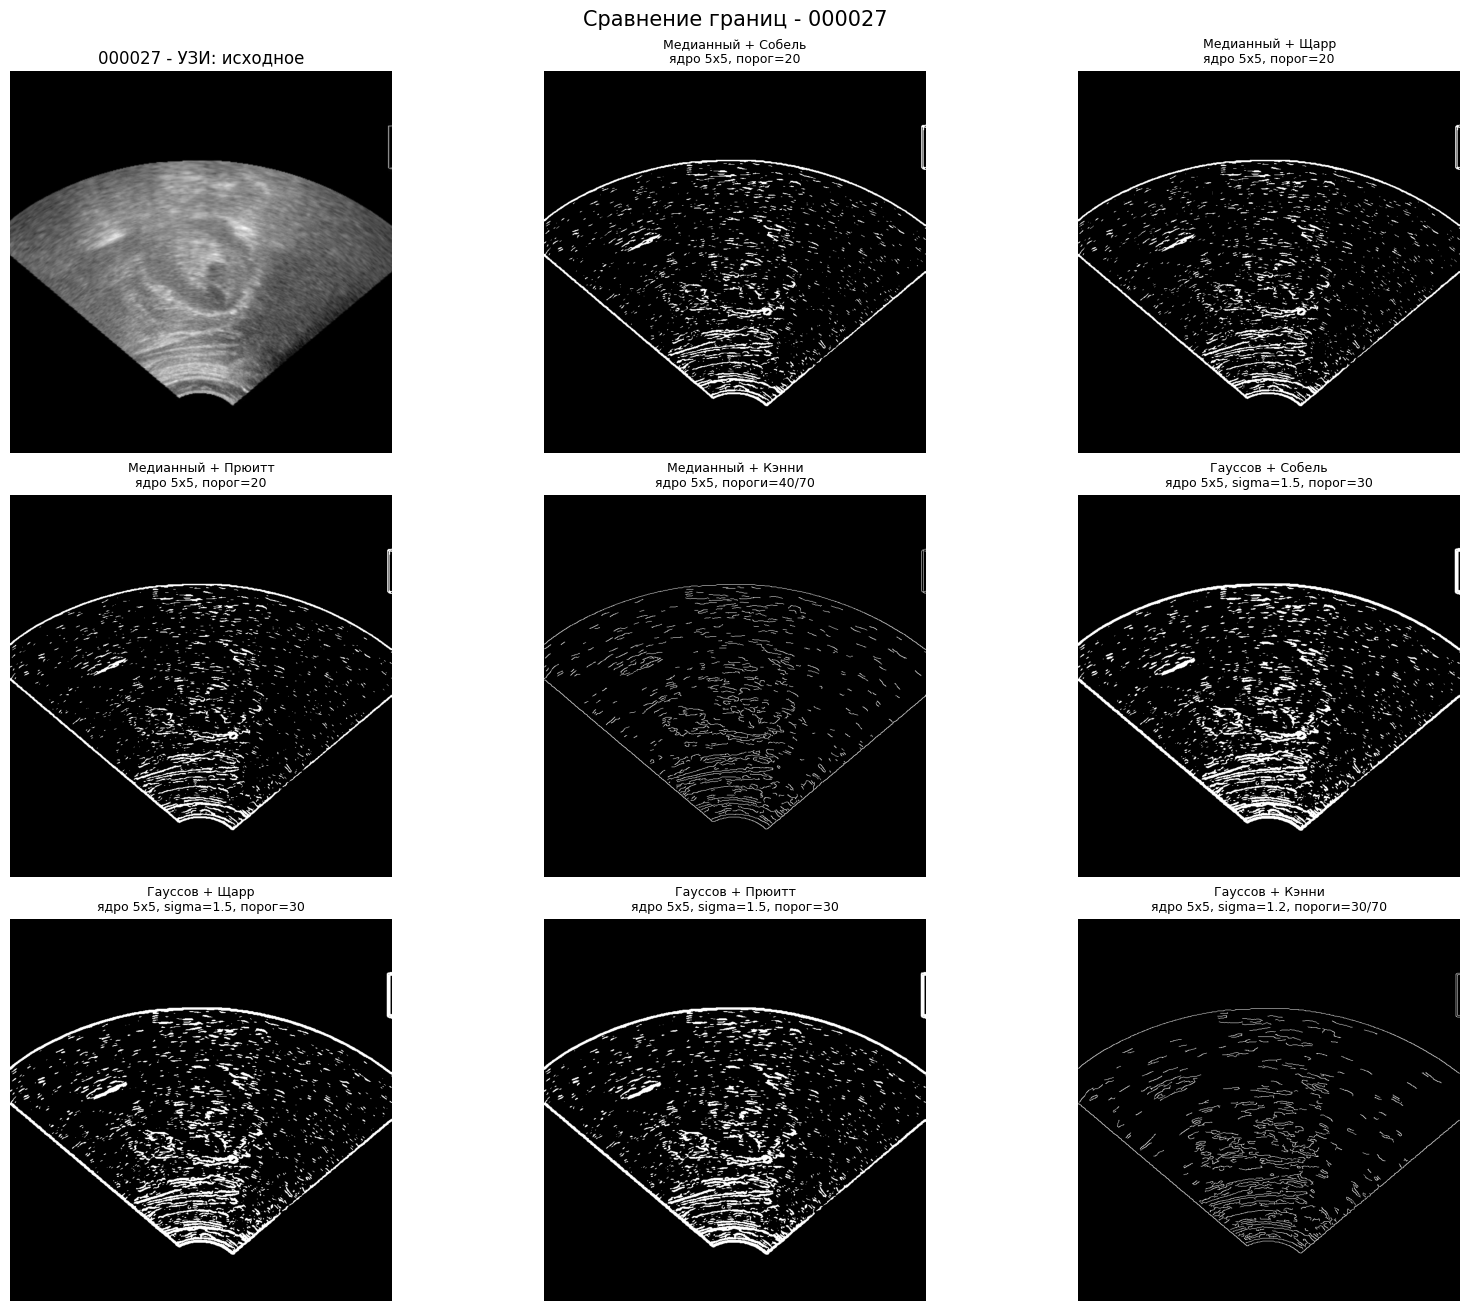

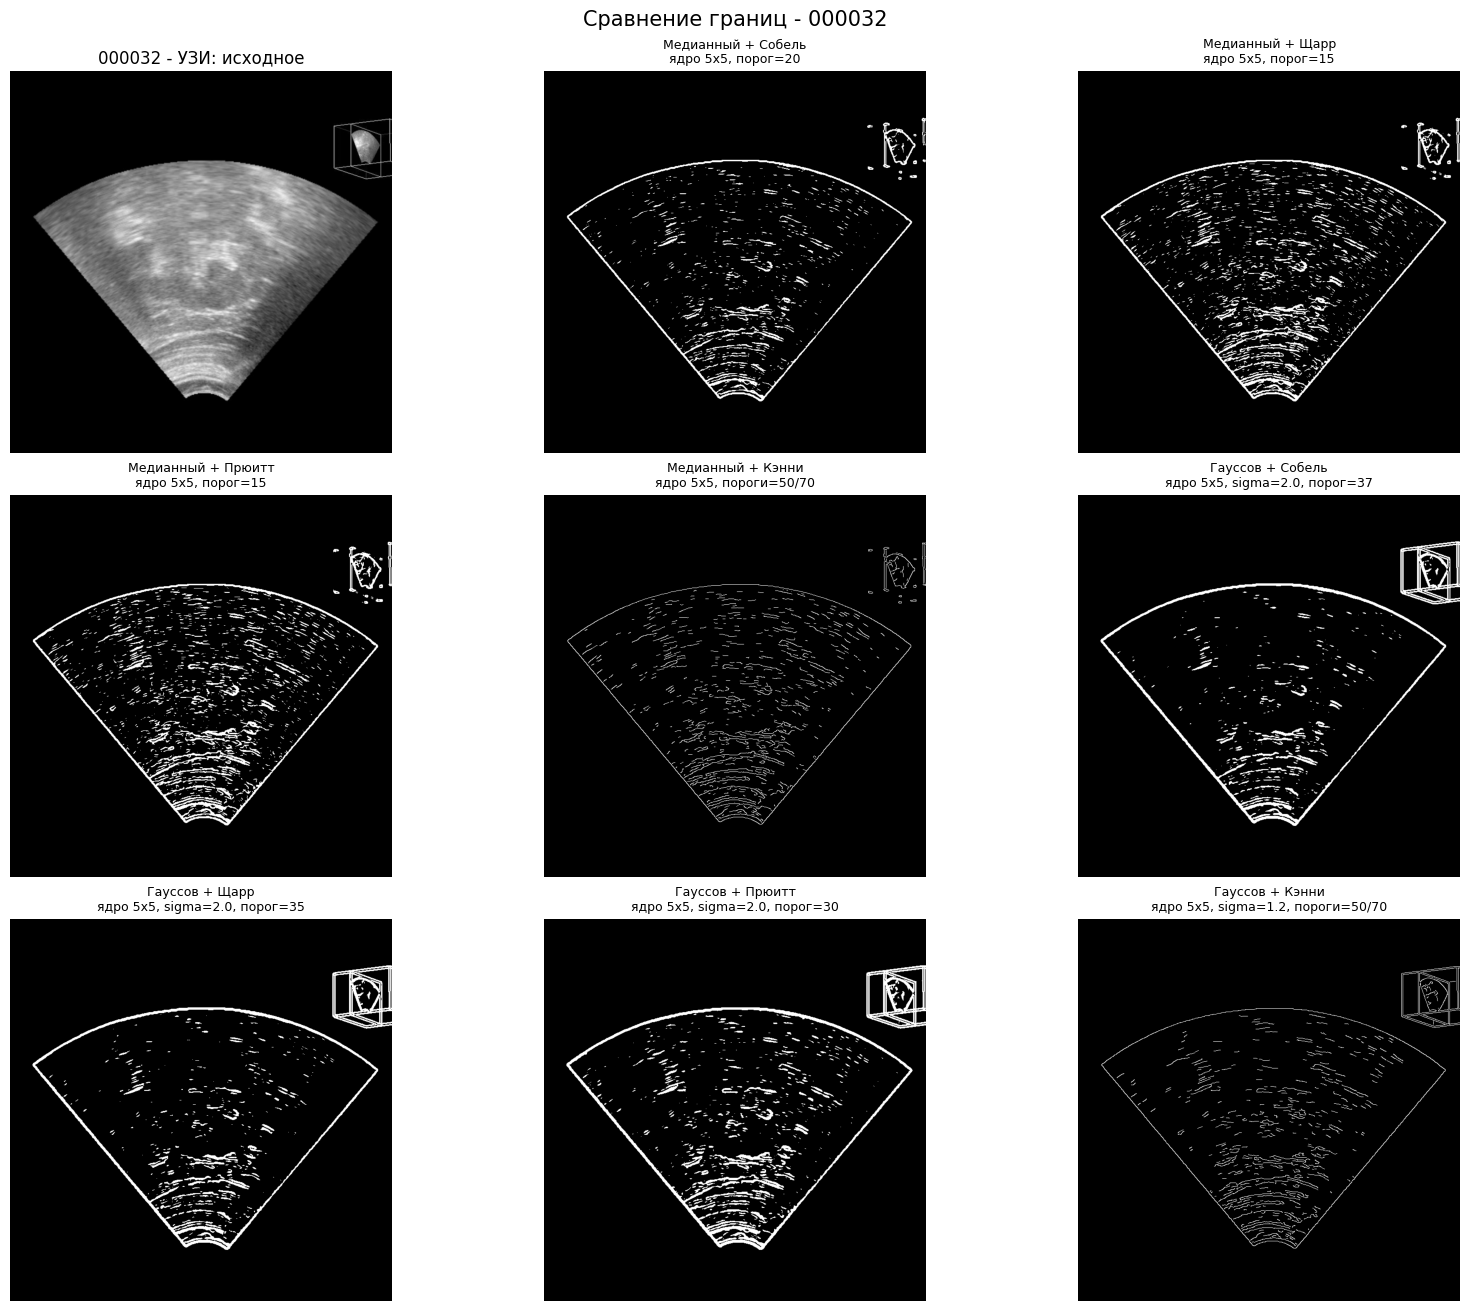

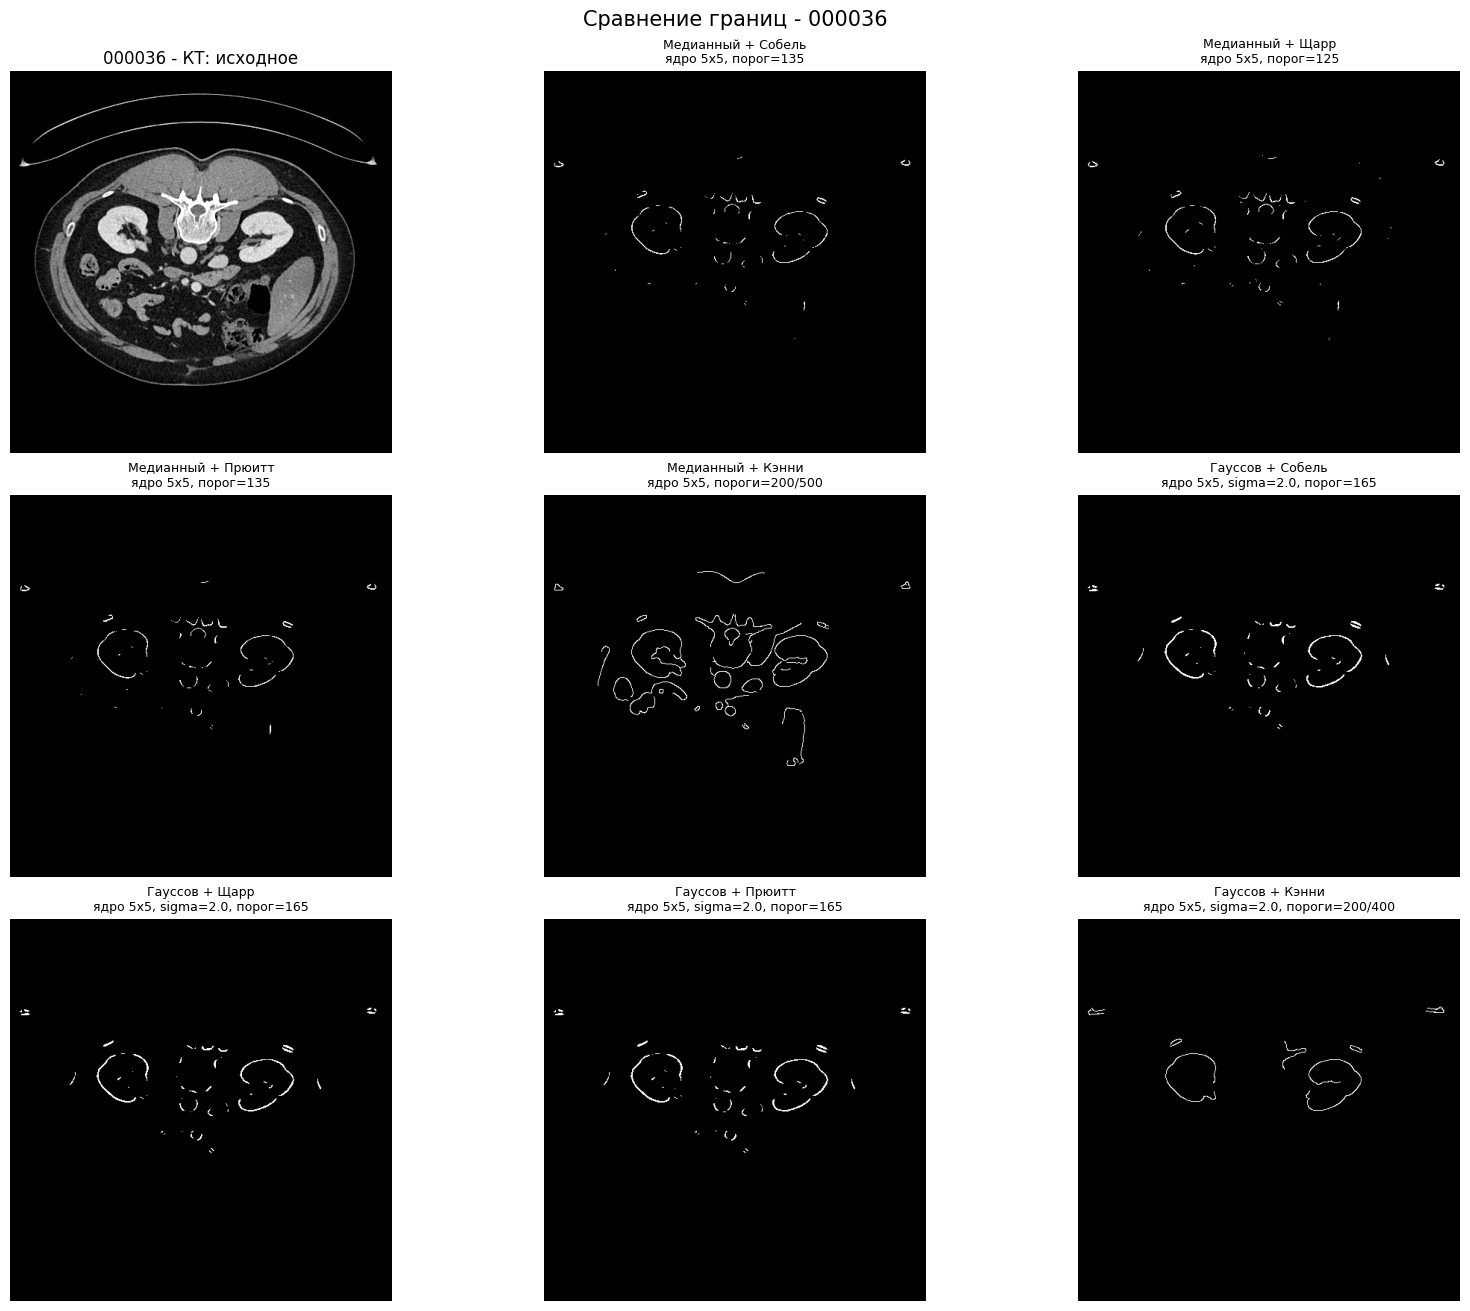

In [60]:
for sample_id, sample in samples.items():
    fig, axes = plt.subplots(3, 3, figsize=(16, 13), constrained_layout=True)
    axes = axes.ravel()

    axes[0].imshow(sample["image"], cmap="gray", vmin=0, vmax=255)
    axes[0].set_title(f'{sample_id} - {sample["type"]}: исходное')

    for ax, (combination, result) in zip(axes[1:], processed[sample_id].items()):
        ax.imshow(result["image"], cmap="gray", vmin=0, vmax=255)
        ax.set_title(
            f"{combination}\n{format_parameters(result['params'])}",
            fontsize=9,
        )

    for ax in axes:
        ax.axis("off")

    fig.suptitle(f"Сравнение границ - {sample_id}", fontsize=15)
    plt.show()


## Вывод

Наиболее чёткие границы для каждого изображения:


000001 - Гауссов + Прюитт

000027 - Медианный + Кэнни

000032 - Гауссов + Собель

000036 - Гауссов + Кэнни